In [1]:
%load_ext autoreload
%autoreload 2

# Customer Churn Prediction

A telecom company is losing customers to competitors. The sales and marketing team wants to know **which customers are likely to leave next month**, so they can offer them an incentive to stay.

- **Data:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (7,043 customers)
- **Target:** `Churn` (Yes/No)

The logic lives in the `telco_churn` package (`src/telco_churn/`). This notebook calls it and explains the decisions.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from telco_churn.data import (
    CATEGORICAL_COLUMNS,
    NUMERIC_COLUMNS,
    TARGET,
    clean_data,
    load_raw_data,
    split_features_target,
)
from telco_churn.features import ENGINEERED_COLUMNS, add_features, build_preprocessor
from telco_churn.model import (
    candidate_models,
    cross_validate_models,
    load_model,
    save_model,
    split_train_test,
    train_model,
)
from telco_churn.plots import (
    churn_rate_gaps,
    plot_churn_rate,
    plot_churn_rate_gaps,
    plot_churn_rate_grid,
    plot_numeric_by_churn,
    plot_target_distribution,
    set_style,
)

set_style()

## 1. Loading and cleaning the data

In [3]:
raw = load_raw_data()
raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Column types

In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` should be a number, but it was read as text (`str`). That means at least one value in the column can't be parsed as a number.

In [5]:
total_numeric = pd.to_numeric(raw["TotalCharges"], errors="coerce")
unparseable = total_numeric.isna()

print(f"Rows that are not a number: {unparseable.sum()}")
print(f"Their values: {raw.loc[unparseable, 'TotalCharges'].unique().tolist()}")
raw.loc[unparseable, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Rows that are not a number: 11
Their values: [' ']


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [6]:
# Are these exactly the customers with tenure == 0?
new_customers = raw["tenure"] == 0
print(f"Customers with tenure == 0: {new_customers.sum()}")
print(f"Same rows as the blanks: {(new_customers == unparseable).all()}")

Customers with tenure == 0: 11
Same rows as the blanks: True


All 11 blanks are a single space `" "`, and they are exactly the 11 customers with `tenure == 0`. These are **new customers who have not been billed yet**, so their true total charge is **0**. It is not an unknown value.

That's why we fill with 0 instead of dropping the rows or filling with an average:
- dropping would discard real (if brand-new) customers;
- the mean or median would invent charges these customers never paid.

Only these 11 values are not numbers, so `errors="coerce"` is safe here.

### Number of distinct values per column

In [7]:
raw.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

- `customerID` is different for every row (7,043 values). It says nothing about churn and would only let a model memorise individual customers, so we **drop** it.
- `SeniorCitizen` has 2 values, but is stored as 0/1 while the other yes/no columns (`Partner`, `Dependents`, …) use "No"/"Yes". We convert it to "No"/"Yes" so it's encoded like the other categories and not scaled as a number.
- `tenure`, `MonthlyCharges` and `TotalCharges` are the only real numeric columns.
- All other columns are categories with 2–4 values.

### Cleaning

`clean_data` applies these decisions to a copy of the data (`raw` is unchanged):

| Column | Change | Reason |
|---|---|---|
| `TotalCharges` | text → number, blanks → 0 | tenure 0, not billed yet |
| `SeniorCitizen` | 0/1 → "No"/"Yes" | same form as other yes/no columns |
| `Churn` | "No"/"Yes" → 0/1 | scikit-learn treats 1 as the positive class; churn rate = mean |
| `customerID` | dropped | identifier, not a feature |

In [8]:
df = clean_data(raw)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   str    
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [9]:
assert df.isna().sum().sum() == 0, "cleaning left missing values"

X, y = split_features_target(df)
print(f"X: {X.shape}, y: {y.shape}")
print(f"Churn rate: {y.mean():.1%}")

X: (7043, 19), y: (7043,)
Churn rate: 26.5%


## 2. Exploratory analysis

Three questions: how many customers churn, which customers churn, and what that means for the model.

### 2.1 How many customers churn?

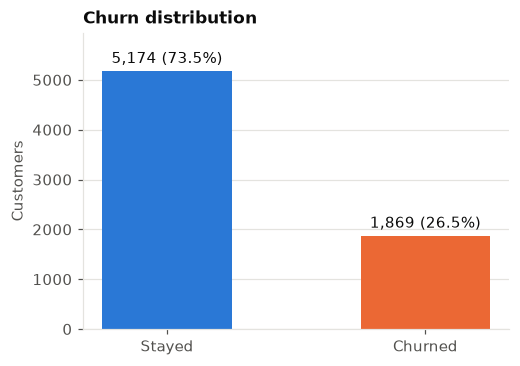

In [10]:
plot_target_distribution(y)
plt.show()

**26.5% of customers churned**, about 1 in 4. The classes are **imbalanced**.

This means accuracy is misleading: a model that always predicts "stays" is **73.5% accurate** but finds no churners at all. So in the following steps we use:
- **stratified cross-validation**, so every fold keeps the 26.5% churn rate;
- **class weights**, which make mistakes on churners cost more during training (tested in step 4);
- **metrics for the churn class** (recall, precision, F1, ROC-AUC, PR-AUC) instead of accuracy.

### 2.2 Contract type

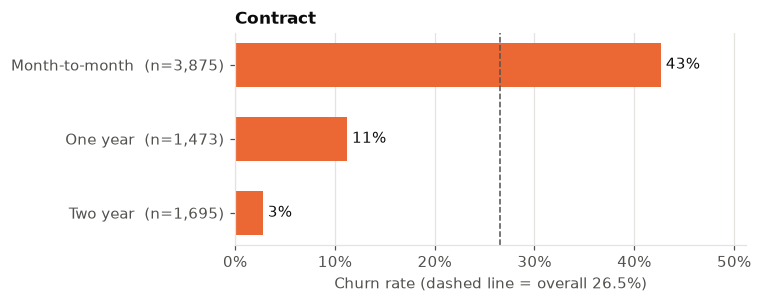

In [11]:
plot_churn_rate(df, "Contract")
plt.show()

Contract is the clearest signal in the data. **Month-to-month customers churn at 42.7%**, two-year customers at only **2.8%** (15× less). Month-to-month is also the largest group (55% of customers).

Leaving costs a month-to-month customer nothing, so a discount for moving to a 1- or 2-year contract is an obvious retention offer. *Caveat:* this is a correlation, not proof of cause. Loyal customers may simply choose longer contracts.

### 2.3 Which other features matter?

To compare all 16 categorical features at once, we take the **gap between the highest and lowest churn rate** within each feature. A large gap means the feature separates churners well.

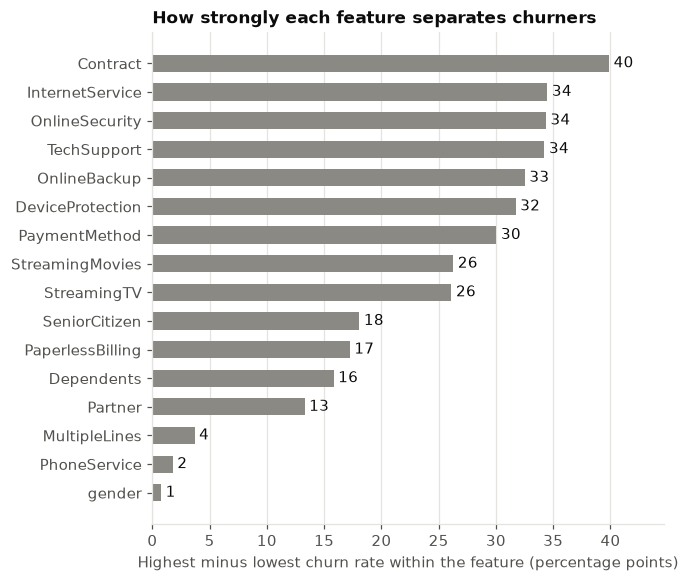

In [12]:
plot_churn_rate_gaps(churn_rate_gaps(df, CATEGORICAL_COLUMNS))
plt.show()

OnlineSecurity, TechSupport, OnlineBackup and DeviceProtection show the same pattern, so below we look at one of them, together with the other strongest features:

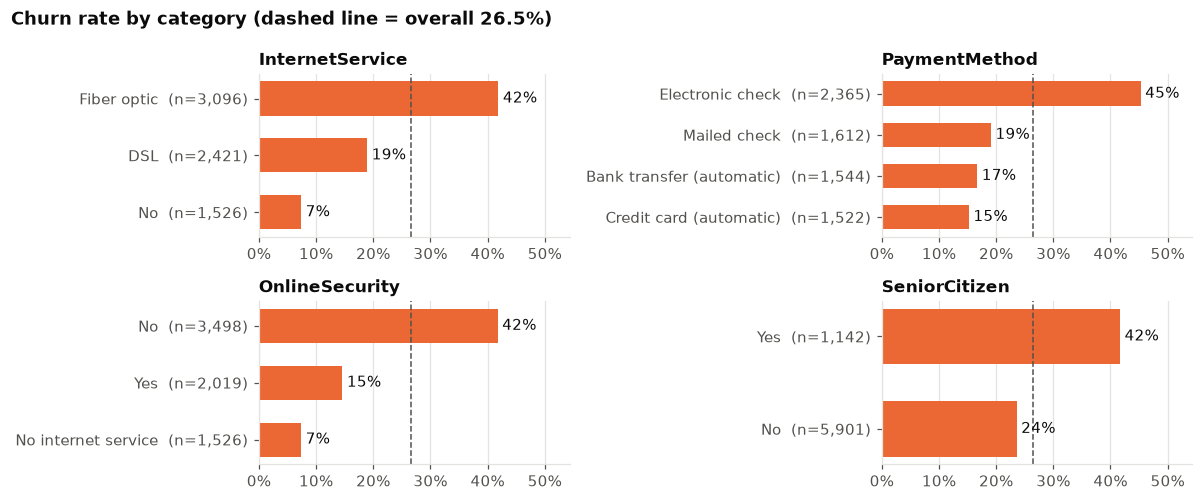

In [13]:
plot_churn_rate_grid(df, ["InternetService", "PaymentMethod", "OnlineSecurity", "SeniorCitizen"], ncols=2)
plt.show()

**Higher churn:**
- **fiber optic** internet: 41.9% (DSL 19.0%);
- paying by **electronic check**: 45.3% (automatic payments 15–17%);
- **no online security**: 41.8% vs 14.6% with it. The same holds for tech support, backup and device protection, so these add-ons are possible retention offers;
- **senior citizens**: 41.7% vs 23.6%.

**Barely matters:** gender, PhoneService and MultipleLines (under 4 points). We keep them anyway, since the model can learn to ignore them.

*Note:* the six add-on columns (OnlineSecurity … StreamingMovies) all include a "No internet service" category. It is the same 1,526 customers in each, with only 7.4% churn, and it makes their gaps look larger. For streaming, most of the gap comes from this group: among internet customers, streaming yes vs no differs by only 3–4 points.

### 2.4 Numeric features

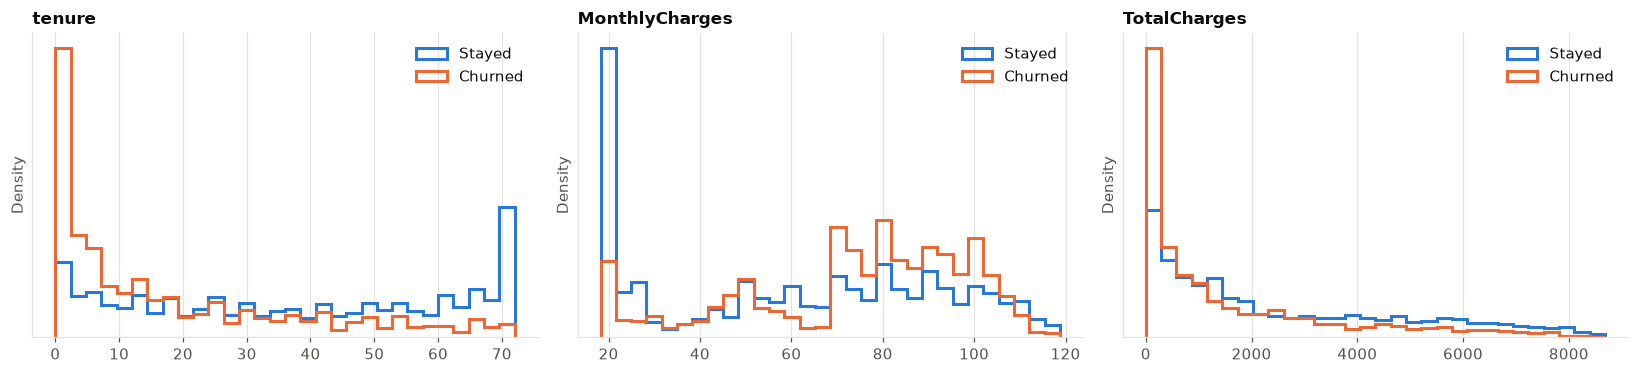

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, column in zip(axes, NUMERIC_COLUMNS):
    plot_numeric_by_churn(df, column, ax=ax)
fig.tight_layout()
plt.show()

In [15]:
df.groupby(TARGET)[NUMERIC_COLUMNS].median().rename(index={0: "Stayed", 1: "Churned"})

,tenure,MonthlyCharges,TotalCharges
Churn,,,
Stayed,38.0,64.425,1679.525
Churned,10.0,79.650,703.550


In [16]:
# Is TotalCharges just tenure × MonthlyCharges?
df["TotalCharges"].corr(df["tenure"] * df["MonthlyCharges"]).round(3)

np.float64(1.0)

- **Churners leave early:** median tenure is 10 months, vs 38 for customers who stayed.
- **Churners pay more per month:** median 79.65 vs 64.43. The big group at about 20 per month (phone only, no internet) rarely churns.
- **TotalCharges adds almost nothing new.** It correlates 1.0 with tenure × MonthlyCharges, and it's lower for churners only because they leave sooner.

### Summary

- **Imbalanced target (26.5%)**: stratified CV and churn-focused metrics (class weights are tested in step 4).
- **Highest risk:** new, month-to-month, fiber-optic customers paying by electronic check, without add-ons like online security or tech support.
- **TotalCharges** mostly repeats tenure × MonthlyCharges, so it adds little information of its own.

## 3. Feature engineering and preprocessing

We add two new features, then scale and encode everything. All of it is packaged in one scikit-learn pipeline (`build_preprocessor`), so that:
- in cross-validation, the scaler is re-fitted on the training folds only (no leakage);
- the REST API can pass raw customer data straight to the saved model, with no separate copy of the feature code.

### 3.1 New features

| Feature | Definition | Idea |
|---|---|---|
| AvgMonthlyCharges | TotalCharges / tenure | average amount actually paid per month |
| NumAddons | how many of the 6 add-on services (OnlineSecurity … StreamingMovies) the customer has | more services, more reasons to stay |

In [17]:
X_feat = add_features(X)
X_feat[ENGINEERED_COLUMNS].describe().round(2)

,AvgMonthlyCharges,NumAddons
count,7043.00,7043.00
mean,64.76,2.04
std,30.19,1.85
min,13.78,0.00
25%,35.94,0.00
50%,70.34,2.00
75%,90.17,3.00
max,121.40,6.00


In [18]:
# new customers: tenure == 0, so TotalCharges / tenure would be 0 / 0
X_feat.loc[X_feat["tenure"] == 0, ["tenure", "MonthlyCharges", "TotalCharges", *ENGINEERED_COLUMNS]].head()

,tenure,MonthlyCharges,TotalCharges,AvgMonthlyCharges,NumAddons
488,0,52.55,0.0,52.55,4
753,0,20.25,0.0,20.25,0
936,0,80.85,0.0,80.85,5
1082,0,25.75,0.0,25.75,0
1340,0,56.05,0.0,56.05,5


The 11 new customers have no billing history yet, so 0 / 0 has no answer. They get their current **MonthlyCharges** instead, because that is what they will pay on average. Using 0 would wrongly say they pay nothing, and leaving `NaN` would break the model.

#### AvgMonthlyCharges

In [19]:
avg, monthly = X_feat["AvgMonthlyCharges"], X_feat["MonthlyCharges"]
print(f"Correlation with MonthlyCharges: {avg.corr(monthly):.3f}")
print(f"Median difference from MonthlyCharges: {(avg - monthly).abs().median():.2f}")
print(f"Correlation of the price change (MonthlyCharges - AvgMonthlyCharges) with churn: "
      f"{(monthly - avg).corr(y):.3f}")

Correlation with MonthlyCharges: 0.996
Median difference from MonthlyCharges: 1.15
Correlation of the price change (MonthlyCharges - AvgMonthlyCharges) with churn: 0.002


AvgMonthlyCharges is **almost the same as MonthlyCharges** (correlation 0.996). For the median customer, the two differ by only about 1 per month. As the EDA showed, TotalCharges in this dataset is essentially tenure × MonthlyCharges, so it contains no real price history.

We also tried the **price change** (current price minus the average paid). It has no relation to churn (correlation 0.002), so we didn't add it.

We keep AvgMonthlyCharges as the brief's example feature, but don't expect it to help much. The overlap with MonthlyCharges does no harm: regularised models handle correlated features.

#### NumAddons

In [20]:
df_feat = X_feat.assign(**{TARGET: y})
has_internet = df_feat["InternetService"] != "No"

print(f"0 add-ons, all customers:      {df_feat.loc[df_feat['NumAddons'] == 0, TARGET].mean():.1%}")
print(f"0 add-ons, internet customers: {df_feat.loc[has_internet & (df_feat['NumAddons'] == 0), TARGET].mean():.1%}")
print(f"No internet (always 0 add-ons): {df_feat.loc[~has_internet, TARGET].mean():.1%}")

0 add-ons, all customers:      21.4%
0 add-ons, internet customers: 52.2%
No internet (always 0 add-ons): 7.4%


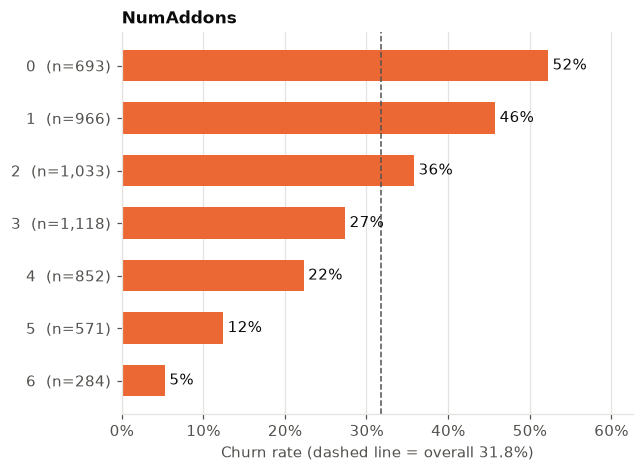

In [21]:
# internet customers only (customers without internet can't have add-ons)
plot_churn_rate(df_feat[has_internet], "NumAddons", sort_by_rate=False)
plt.show()

This is a strong feature. **Among internet customers, churn falls with every extra add-on**, from 52% with none to 5% with all six. (The dashed line here is the churn rate of internet customers, 31.8%.)

Customers *without* internet always have 0 add-ons, and only 7.4% of them churn. Mixed together, the "0 add-ons" group looks safe (21.4%) and hides the pattern. That's why the chart shows internet customers only. The model can still tell the two groups apart, because it also gets InternetService.

### 3.2 Scaling and encoding

| Columns | Transformer | Why |
|---|---|---|
| 3 numeric + 2 new | `StandardScaler` | rescales to mean 0 and std 1. Ranges differ a lot (tenure 0–72, TotalCharges 0–8,700), and logistic regression's regularisation penalises all coefficients equally, so features must be on the same scale |
| 16 categorical | `OneHotEncoder` | one 0/1 column per category. Numbering categories 0, 1, 2 would make up an order (is "Mailed check" *between* the other methods?) |

Encoder settings:
- `drop="if_binary"`: a yes/no column becomes one column (`Partner_Yes`) instead of two.
- `handle_unknown="ignore"`: a category never seen in training becomes all zeros instead of an error. Caveat: for a yes/no column, "all zeros" means "No". So the API must check that incoming values are valid instead of relying on this.
- `sparse_output=False`: returns a normal table instead of a compressed (sparse) matrix, so it's easy to inspect.

In [22]:
preprocessor = build_preprocessor().set_output(transform="pandas")
X_ready = preprocessor.fit_transform(X)  # fitted on all data only to inspect it

print(f"{X.shape[1]} raw columns -> {X_ready.shape[1]} model-ready columns, "
      f"missing values: {X_ready.isna().sum().sum()}")
X_ready.head()

19 raw columns -> 42 model-ready columns, missing values: 0


,numeric__tenure,numeric__MonthlyCharges,numeric__TotalCharges,numeric__AvgMonthlyCharges,numeric__NumAddons,categorical__gender_Male,categorical__SeniorCitizen_Yes,categorical__Partner_Yes,categorical__Dependents_Yes,categorical__PhoneService_Yes,...,categorical__StreamingMovies_No internet service,categorical__StreamingMovies_Yes,categorical__Contract_Month-to-month,categorical__Contract_One year,categorical__Contract_Two year,categorical__PaperlessBilling_Yes,categorical__PaymentMethod_Bank transfer (automatic),categorical__PaymentMethod_Credit card (automatic),categorical__PaymentMethod_Electronic check,categorical__PaymentMethod_Mailed check
0,-1.277445,-1.160323,-0.992611,-1.156529,-0.561776,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.066327,-0.259629,-0.172165,-0.304408,-0.020519,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-1.236724,-0.362660,-0.958066,-0.354049,-0.020519,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.514251,-0.746535,-0.193672,-0.790302,0.520738,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,-1.236724,0.197365,-0.938874,0.366444,-1.103033,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [23]:
# scaled columns: mean ≈ 0, std ≈ 1
X_ready.filter(like="numeric__").agg(["mean", "std"]).round(2)

,numeric__tenure,numeric__MonthlyCharges,numeric__TotalCharges,numeric__AvgMonthlyCharges,numeric__NumAddons
mean,-0.0,-0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


19 raw columns become **42 numeric columns** with no missing values: 5 scaled numeric columns and 37 one-hot columns.

Here the preprocessor was fitted on all the data, **only to inspect the result**. In step 4 it becomes the first part of the model pipeline, and cross-validation re-fits it on the training folds each time.

## 4. Model training

How we choose the model:
1. Split off a **test set** (20%). It stays untouched until the final evaluation in step 5.
2. Compare models on the **training set** with stratified 5-fold cross-validation.
3. **Main metric: PR-AUC** (average precision). It measures how well the model ranks churners above non-churners, focuses on the churn class, and doesn't depend on a decision threshold. A model that guesses scores 0.265 (the churn rate), a perfect one 1.0. ROC-AUC is reported too.

### 4.1 Train / test split

In [24]:
X_train, X_test, y_train, y_test = split_train_test(X, y)
print(f"train: {X_train.shape[0]:,} customers, churn {y_train.mean():.1%}")
print(f"test:  {X_test.shape[0]:,} customers, churn {y_test.mean():.1%}")

train: 5,634 customers, churn 26.5%
test:  1,409 customers, churn 26.5%


### 4.2 Comparing models

| Model | How it works | Strength | Weakness |
|---|---|---|---|
| Logistic regression | a weighted sum of the features, turned into a probability | simple, fast, explainable (one weight per feature) | only learns simple, additive effects |
| Random forest | many decision trees on random samples of the data, averaged | finds combinations of features by itself | overfits easily, harder to explain |
| Gradient boosting | small trees added one by one, each fixing the previous ones' errors | often the most accurate on tabular data | more settings to tune, harder to explain |

Each model uses the best settings found in our experiments (section 4.3). The random forest is also shown with default settings, to show what overfitting looks like.

`train_pr_auc` is the score on the data the model was trained on. A big gap between it and the validation score (`test_pr_auc`) means **overfitting**.

In [25]:
cv_results = cross_validate_models(candidate_models(), X_train, y_train)
cv_results[["test_roc_auc", "test_pr_auc", "test_pr_auc_std", "train_pr_auc"]].round(3)

,test_roc_auc,test_pr_auc,test_pr_auc_std,train_pr_auc
Logistic regression,0.846,0.662,0.018,0.667
Random forest (default settings),0.827,0.622,0.029,1.000
Random forest,0.847,0.664,0.022,0.750
Gradient boosting,0.849,0.667,0.022,0.701


- The **default random forest** scores a perfect **1.000 on its training data** but only **0.622 on validation**: it memorised the training customers. Requiring at least 20 customers per leaf fixes that (0.664, train 0.750). This is exactly what cross-validation is for: judged on its training data alone, the default forest would look perfect.
- The three tuned models are **very close**: PR-AUC 0.662 to 0.667 and ROC-AUC 0.846 to 0.849. The differences are smaller than the variation between folds (std ≈ 0.02).
- **Logistic regression** doesn't overfit at all (train 0.667 vs validation 0.662).

### 4.3 How we chose these settings

During development we ran these experiments on the training set. They are not repeated here, to keep the notebook short and fast; `scripts/model_experiments.py` reproduces them (about 4 minutes). All scores are validation PR-AUC. The experiments ran with class weights (before we dropped them), so the numbers differ slightly from the table in 4.2.

| Experiment | What we tried | Result |
|---|---|---|
| Hyperparameter search | Logistic regression: all 33 combinations of `C` and L1/L2 penalty. Random forest and gradient boosting: 30 random combinations each of tree depth, leaf size, learning rate, etc. | Logistic regression barely changes (0.658 → 0.661). The tree models gain the most by being **restricted**: random forest 0.616 → 0.666, gradient boosting 0.645 → 0.668 with depth-2 trees |
| Nested CV | the whole search repeated inside each fold, scored on data it never saw | 0.660 / 0.664 / 0.664: the tree models' search scores were slightly flattered, logistic regression's was not |
| Ensemble | average of logistic regression and gradient boosting | best overall (0.669), but less than 0.01 ahead of logistic regression |
| Class weights | `class_weight="balanced"` vs none | same ranking quality, but the average predicted churn probability is **41%** instead of the real **26.5%**, so we use **no class weights** |
| Engineered features | with vs without | no measurable difference (under 0.001) |

Two things stand out:
- The best tree models use **very shallow trees**, so they are close to a simple additive model. Churn here is mostly explained by simple effects (contract, tenure, internet type, …), which logistic regression already captures.
- The engineered features don't help because the model can already compute them: NumAddons is the sum of the six add-on "Yes" columns, and AvgMonthlyCharges ≈ MonthlyCharges (step 3). We keep them because the brief asks for one.

### 4.4 Final choice: logistic regression

We choose **L1-regularised logistic regression** (`C = 0.3`, no class weights):
1. **Practically as accurate:** the best alternative is less than 0.01 PR-AUC better, smaller than the variation between folds.
2. **Explainable:** each feature has one weight that raises or lowers churn risk, so the sales team can see *why* a customer is flagged.
3. **Robust:** it doesn't overfit.
4. **Simple to run:** it trains in a fraction of a second and is easy to retrain every month.
5. **Honest probabilities:** without class weights, a "70% churn risk" really means about 70%.

*Caveat:* some one-hot columns repeat each other (the six "No internet service" columns), so single coefficients must be read with care. In step 5 we explain the model with **permutation importance**, which measures each original feature as a whole.

In [26]:
# train on the full training set and save the whole pipeline (preprocessing + model)
model = train_model(candidate_models()["Logistic regression"], X_train, y_train)
save_model(model)

# sanity check: the saved model loads and returns churn probabilities for raw customer data
load_model().predict_proba(X_train.head(3))[:, 1].round(3)

array([0.333, 0.288, 0.046])

The trained pipeline is saved to `models/churn_model.joblib`. It isn't committed to git; running this notebook recreates it.